# Notebook 05 — Frequency-Domain Diagnostic (decision gate)

**Goal.** Before building/training any spectral two-stream model, test the
*hypothesis* cheaply: do CIFAKE (Stable-Diffusion) images carry a frequency
fingerprint that a hand-crafted spectral feature can separate from REAL —
where the spatial edge feature (EBP, AUC 51.7%) failed?

**Method.** Native-32×32 FFT → log-magnitude → radial (azimuthal) spectral
profile → (i) plot mean REAL-vs-FAKE profiles, (ii) LogReg on the profile,
report test AUC. Same 4k+4k subset / 70-15-15 split / seed 42 as Notebook 01,
so results are comparable to Chapter 5.

**Decision gate (set BEFORE running):**
- spectral-only test AUC **> 0.65** → hypothesis has legs → build two-stream (NB06).
- AUC ≈ 0.50–0.55 → honest negative finding (no exploitable spectral fingerprint
  at 32×32 for SD) → do NOT waste a training run.
- Reference: fixed-EBP edge feature reached only AUC 0.517 (Notebook 01).

No fabricated numbers — every value below is computed at run time.

In [1]:
# ============================================================
# CELL 1: IMPORTS + REPRODUCIBILITY
# ============================================================
!pip install -q datasets 2>/dev/null

import os, gc, numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

SEED = 42
np.random.seed(SEED)
print("Imports OK. SEED =", SEED)

Imports OK. SEED = 42


In [2]:
# ============================================================
# CELL 2: CONFIGURATION
# ============================================================
CONFIG = {
    'hf_dataset_id' : 'dragonintelligence/CIFAKE-image-dataset',
    'n_per_class'   : 4000,          # mirrors Notebook 01 (paper Section 4.1)
    'train_ratio'   : 0.70,
    'val_ratio'     : 0.15,
    'test_ratio'    : 0.15,
    'seed'          : SEED,

    # Spectral feature [NOT STATED IN PAPER -- our design]
    'fft_on'        : 'native32',    # compute FFT on native 32x32 (pre-upscale):
                                     # the 32->224 upscale imprints an identical
                                     # spectral signature on REAL and FAKE, so the
                                     # discriminative signal lives at native res.
    'hf_radius_frac': 0.5,           # "high frequency" = radius > 0.5 * Nyquist

    # Decision gate
    'gate_auc'      : 0.65,
    'ebp_baseline_auc': 0.517,       # fixed-EBP edge feature (Notebook 01)
    'output_dir'    : '/content/nb05_out',
}
# mount Drive for persistent artifacts (like NB01/02/06)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    CONFIG['drive_backup'] = '/content/drive/MyDrive/luanvan_thac_si/notebook05_artifacts'
except Exception as e:
    CONFIG['drive_backup'] = '/content/nb05_artifacts'
    print('No Colab drive; using', CONFIG['drive_backup'])
os.makedirs(CONFIG['output_dir'], exist_ok=True)
os.makedirs(CONFIG['drive_backup'], exist_ok=True)
print('output_dir   :', CONFIG['output_dir'])
print('drive_backup :', CONFIG['drive_backup'])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
output_dir   : /content/nb05_out
drive_backup : /content/drive/MyDrive/luanvan_thac_si/notebook05_artifacts


In [3]:
# ============================================================
# CELL 3: LOAD CIFAKE + BUILD THE SAME SUBSET/SPLIT AS NOTEBOOK 01
# ============================================================
raw_ds = load_dataset(CONFIG['hf_dataset_id'])
lf = raw_ds['train'].features['label']
id2label = {i: n for i, n in enumerate(lf.names)}
FAKE_ID = lf.names.index('FAKE')   # typically 0
REAL_ID = lf.names.index('REAL')   # typically 1
print("Labels:", lf.names, "| FAKE_ID", FAKE_ID, "REAL_ID", REAL_ID)

pool = {FAKE_ID: [], REAL_ID: []}
for split in ['train', 'test']:
    for item in tqdm(raw_ds[split], desc=f'Indexing {split}', leave=False):
        pool[item['label']].append(item['image'])

rng = np.random.default_rng(SEED)
n = CONFIG['n_per_class']
fake_idx = rng.choice(len(pool[FAKE_ID]), size=n, replace=False)
real_idx = rng.choice(len(pool[REAL_ID]), size=n, replace=False)
all_images = [pool[FAKE_ID][i] for i in fake_idx] + [pool[REAL_ID][i] for i in real_idx]
all_labels = [FAKE_ID]*n + [REAL_ID]*n
del pool; gc.collect()

imgs_tv, imgs_test, y_tv, y_test = train_test_split(
    all_images, all_labels, test_size=CONFIG['test_ratio'],
    stratify=all_labels, random_state=SEED)
val_frac = CONFIG['val_ratio'] / (CONFIG['train_ratio'] + CONFIG['val_ratio'])
imgs_train, imgs_val, y_train, y_val = train_test_split(
    imgs_tv, y_tv, test_size=val_frac, stratify=y_tv, random_state=SEED)
y_train = np.array(y_train); y_test = np.array(y_test)
print(f"train:{len(imgs_train)}  val:{len(imgs_val)}  test:{len(imgs_test)}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Labels: ['FAKE', 'REAL'] | FAKE_ID 0 REAL_ID 1


Indexing train:   0%|          | 0/100000 [00:00<?, ?it/s]

Indexing test:   0%|          | 0/20000 [00:00<?, ?it/s]

train:5600  val:1200  test:1200


In [4]:
# ============================================================
# CELL 4: SPECTRAL FEATURE FUNCTIONS
# ============================================================
# Pipeline per image (native 32x32):
#   grayscale [0,1] -> FFT2 -> fftshift -> log(1+|F|) -> radial average -> 1D profile.
# The radial (azimuthal) average collapses the 2D spectrum to a compact,
# rotation-robust 1D curve (Durall et al., 2020 style).

def to_gray32(pil):
    g = pil.convert('L').resize((32, 32), Image.BILINEAR)
    return np.asarray(g, dtype=np.float32) / 255.0

def log_mag_spectrum(gray):
    F = np.fft.fftshift(np.fft.fft2(gray))
    return np.log1p(np.abs(F))                      # 32x32 log-magnitude

# Precompute radial bin indices for a 32x32 grid (center = 16,16)
_H = _W = 32
_cy, _cx = _H // 2, _W // 2
_yy, _xx = np.indices((_H, _W))
_R = np.sqrt((_yy - _cy)**2 + (_xx - _cx)**2).astype(int)
_NR = np.bincount(_R.ravel())
N_BINS = len(_NR)                                   # ~23 for 32x32
NYQ = _W // 2

def radial_profile(mag):
    tb = np.bincount(_R.ravel(), mag.ravel())
    return tb / np.maximum(_NR, 1)                  # length N_BINS

def features(imgs):
    profs, spec2d = [], []
    for im in tqdm(imgs, desc='spectra', leave=False):
        m = log_mag_spectrum(to_gray32(im))
        profs.append(radial_profile(m)); spec2d.append(m)
    return np.array(profs), np.array(spec2d)

print("N_BINS (radial features) =", N_BINS, "| Nyquist radius =", NYQ)

N_BINS (radial features) = 23 | Nyquist radius = 16


In [5]:
# ============================================================
# CELL 5: COMPUTE SPECTRA FOR TRAIN + TEST
# ============================================================
Xtr, _      = features(imgs_train)
Xte, S2D_te = features(imgs_test)
print("Xtr", Xtr.shape, "| Xte", Xte.shape)

spectra:   0%|          | 0/5600 [00:00<?, ?it/s]

spectra:   0%|          | 0/1200 [00:00<?, ?it/s]

Xtr (5600, 23) | Xte (1200, 23)


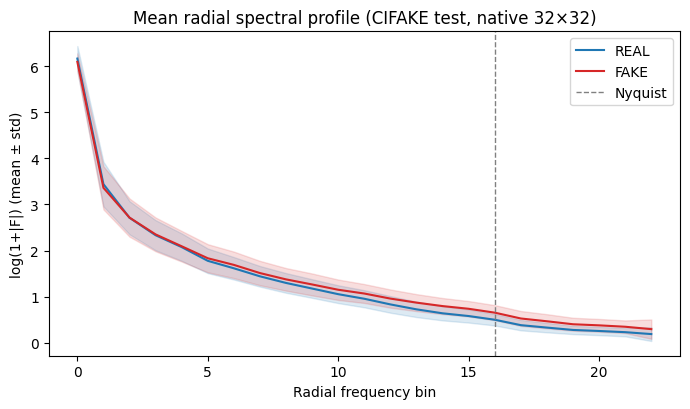

In [6]:
# ============================================================
# CELL 6: VISUAL CHECK 1 -- mean radial spectral profile REAL vs FAKE
# ============================================================
# If the curves separate (esp. at high frequency), a fingerprint exists.
prof_fake = Xte[y_test == FAKE_ID]
prof_real = Xte[y_test == REAL_ID]
freqs = np.arange(N_BINS)

plt.figure(figsize=(7, 4.2))
for prof, name, c in [(prof_real, 'REAL', 'tab:blue'), (prof_fake, 'FAKE', 'tab:red')]:
    mu, sd = prof.mean(0), prof.std(0)
    plt.plot(freqs, mu, label=name, color=c)
    plt.fill_between(freqs, mu - sd, mu + sd, color=c, alpha=0.15)
plt.axvline(NYQ, ls='--', c='gray', lw=1, label='Nyquist')
plt.xlabel('Radial frequency bin'); plt.ylabel('log(1+|F|) (mean ± std)')
plt.title('Mean radial spectral profile (CIFAKE test, native 32×32)')
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(CONFIG['output_dir'], 'fig_radial_profile.png'), dpi=140)
plt.show()

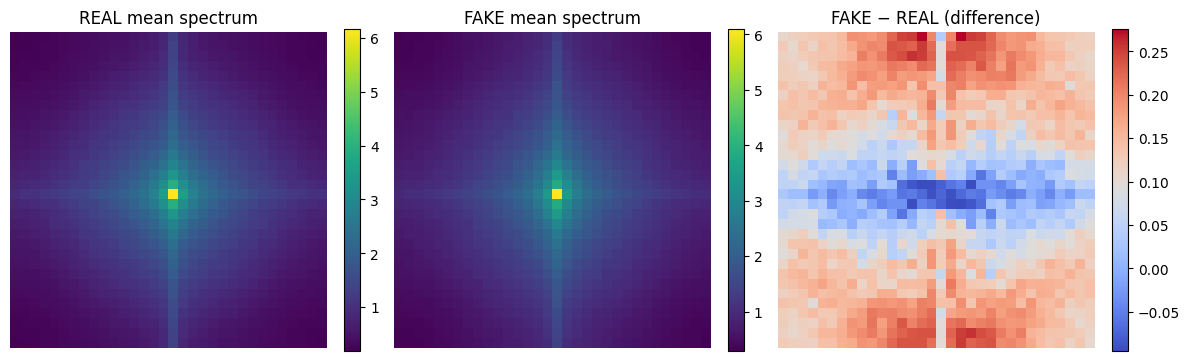

Look for grid/peak patterns or a high-frequency energy gap in the difference map.


In [7]:
# ============================================================
# CELL 7: VISUAL CHECK 2 -- mean 2D log-spectrum REAL / FAKE / difference
# ============================================================
mean_real2d = S2D_te[y_test == REAL_ID].mean(0)
mean_fake2d = S2D_te[y_test == FAKE_ID].mean(0)
diff2d = mean_fake2d - mean_real2d

fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a, img, t in [(ax[0], mean_real2d, 'REAL mean spectrum'),
                  (ax[1], mean_fake2d, 'FAKE mean spectrum'),
                  (ax[2], diff2d,      'FAKE − REAL (difference)')]:
    im = a.imshow(img, cmap='viridis' if t != 'FAKE − REAL (difference)' else 'coolwarm')
    a.set_title(t); a.axis('off'); fig.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['output_dir'], 'fig_2d_spectrum.png'), dpi=140)
plt.show()
print("Look for grid/peak patterns or a high-frequency energy gap in the difference map.")

In [8]:
# ============================================================
# CELL 8: SINGLE-STATISTIC DIAGNOSTIC -- high-frequency energy ratio
# ============================================================
# EBP-style scalar probe + Cohen's d (independent of any classifier).
hf_cut = int(CONFIG['hf_radius_frac'] * NYQ)
def hf_ratio(prof):                      # high-freq / total radial energy
    return prof[hf_cut:].sum() / (prof.sum() + 1e-8)

hf = np.array([hf_ratio(p) for p in Xte])
hf_fake, hf_real = hf[y_test == FAKE_ID], hf[y_test == REAL_ID]
pooled_sd = np.sqrt((hf_fake.var(ddof=1) + hf_real.var(ddof=1)) / 2)
cohens_d = (hf_fake.mean() - hf_real.mean()) / (pooled_sd + 1e-12)
print(f"HF energy ratio  FAKE={hf_fake.mean():.4f}  REAL={hf_real.mean():.4f}")
print(f"Cohen's d (FAKE vs REAL) = {cohens_d:+.3f}  "
      f"({'negligible' if abs(cohens_d)<0.2 else 'small' if abs(cohens_d)<0.5 else 'medium' if abs(cohens_d)<0.8 else 'large'})")

HF energy ratio  FAKE=0.3383  REAL=0.2999
Cohen's d (FAKE vs REAL) = +1.090  (large)


In [9]:
# ============================================================
# CELL 9: LOGISTIC REGRESSION ON RADIAL PROFILE -> TEST AUC (decision gate)
# ============================================================
scaler = StandardScaler().fit(Xtr)
clf = LogisticRegression(max_iter=2000, C=1.0).fit(scaler.transform(Xtr), y_train)

# score = P(FAKE); positive class = FAKE
classes = list(clf.classes_)
pf_te = clf.predict_proba(scaler.transform(Xte))[:, classes.index(FAKE_ID)]
pred_te = np.where(pf_te >= 0.5, FAKE_ID, REAL_ID)

auc = roc_auc_score((y_test == FAKE_ID).astype(int), pf_te)
acc = accuracy_score(y_test, pred_te) * 100
f1  = f1_score(y_test, pred_te, pos_label=FAKE_ID) * 100
print(f"Spectral-only (radial profile + LogReg)  ->  "
      f"AUC={auc:.3f}  Accuracy={acc:.2f}%  F1={f1:.2f}%")

Spectral-only (radial profile + LogReg)  ->  AUC=0.884  Accuracy=81.33%  F1=81.33%


In [10]:
# ============================================================
# CELL 10: DECISION GATE
# ============================================================
gate, ebp = CONFIG['gate_auc'], CONFIG['ebp_baseline_auc']
print("="*60)
print(" FREQUENCY-DOMAIN DECISION GATE")
print("="*60)
print(f"  spectral-only AUC        : {auc:.3f}")
print(f"  fixed-EBP edge AUC (N01) : {ebp:.3f}")
print(f"  gate threshold           : {gate:.3f}")
print("-"*60)
if auc >= gate:
    print(f"  PROCEED  -> AUC {auc:.3f} ≥ {gate:.3f}.")
    print("  A spectral fingerprint is exploitable. Build the spectral")
    print("  two-stream (NB06) and run multi-seed vs ViT-only.")
elif auc > ebp + 0.05:
    print(f"  WEAK signal -> AUC {auc:.3f} beats EBP ({ebp:.3f}) but is below")
    print(f"  the gate ({gate:.3f}). Marginal: consider 2D-CNN on the full")
    print("  spectrum or DCT before committing to two-stream training.")
else:
    print(f"  STOP  -> AUC {auc:.3f} ≈ chance / no better than EBP ({ebp:.3f}).")
    print("  Honest finding: no exploitable spectral fingerprint at 32×32 for")
    print("  Stable-Diffusion CIFAKE. Do NOT train the two-stream; report this")
    print("  as a negative result (consistent with diffusion≠GAN spectra).")
print("="*60)

import csv
with open(os.path.join(CONFIG['output_dir'], 'spectral_diagnostic.csv'), 'w', newline='') as fcsv:
    w = csv.writer(fcsv); w.writerow(['metric', 'value'])
    for k, v in [('spectral_auc', auc), ('spectral_acc', acc), ('spectral_f1', f1),
                 ('hf_cohens_d', cohens_d), ('ebp_baseline_auc', ebp), ('gate', gate)]:
        w.writerow([k, round(float(v), 4)])
print("Saved spectral_diagnostic.csv")

 FREQUENCY-DOMAIN DECISION GATE
  spectral-only AUC        : 0.884
  fixed-EBP edge AUC (N01) : 0.517
  gate threshold           : 0.650
------------------------------------------------------------
  PROCEED  -> AUC 0.884 ≥ 0.650.
  A spectral fingerprint is exploitable. Build the spectral
  two-stream (NB06) and run multi-seed vs ViT-only.
Saved spectral_diagnostic.csv


In [11]:
# ============================================================
# CELL 11: BACKUP FIGURES + CSV TO DRIVE
# ============================================================
import shutil
saved = []
for f in os.listdir(CONFIG['output_dir']):
    shutil.copy(os.path.join(CONFIG['output_dir'], f),
                os.path.join(CONFIG['drive_backup'], f))
    saved.append(f)
print('Backed up to', CONFIG['drive_backup'])
for f in sorted(saved):
    print('  -', f)
print('\nFigures for thesis Section 5.3.6:')
print('  fig_radial_profile.png  (radial spectral profile REAL vs FAKE)')
print('  fig_2d_spectrum.png     (mean 2D spectrum REAL / FAKE / difference)')

Backed up to /content/drive/MyDrive/luanvan_thac_si/notebook05_artifacts
  - fig_2d_spectrum.png
  - fig_radial_profile.png
  - spectral_diagnostic.csv

Figures for thesis Section 5.3.6:
  fig_radial_profile.png  (radial spectral profile REAL vs FAKE)
  fig_2d_spectrum.png     (mean 2D spectrum REAL / FAKE / difference)
